# OUTPUT to VTK for paraview

extract the permeability data from PFLOTRAN dataset for display in paraview

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [4]:
#pip install vtk

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.1/92.1 MB 63.8 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import h5py as h5
import os
import sys
import numpy as np
import pandas as pd
sys.path.insert(0,'/global/homes/z/zc727/HFR/notebooks')
from myfunc import print_structure

import vtk
from vtk.util import numpy_support
import shapefile
from shapely.geometry import Point, Polygon

## check the permeability data from output

In [3]:
filepath = '/pscratch/sd/z/zc727/'+'model_iso_perm/HFR-iso-perm.h5'
#filepath = '/pscratch/sd/z/zc727/'+'model_aniso_perm_only_alluvium/perm_only_alluvium.h5'
#filepath = '/pscratch/sd/z/zc727/'+'model_aniso_perm_except_basalt/perm_all_except_basalt.h5'
# Open the file in read mode
with h5.File(filepath, "r") as input_h5:
    # Assuming the datasets 'Permeability X [m^2]' and 'Material ID' are in the root group or first group
    first_group = input_h5[list(input_h5.keys())[0]]
    
    # Read the datasets
    permeability_x = first_group['Permeability X [m^2]'][:]
    material_id = first_group['Material ID'][:]
    
# Plotting
plt.scatter(material_id, permeability_x, alpha=0.5)
plt.title('Permeability in all region from output h5 file')
plt.ylabel('Permeability X [m^2]')
plt.xlabel('Material ID')
plt.yscale('log')
plt.show()    

KeyError: "Unable to synchronously open object (object 'Permeability X [m^2]' doesn't exist)"

## extract data from big_HDF5 (all region) to VTK

In [15]:
# Read data from HDF5 files
filepath1 = '/pscratch/sd/z/zc727/model_perm/HFR-model-100m-flow_perm.h5'
with h5.File(filepath1, 'r') as input_h5:
    first_group = input_h5[list(input_h5.keys())[0]]
    permeability_x = first_group['Permeability X [m^2]'][:]
    material_id = first_group['Material ID'][:]
    coord_vertices = input_h5['Domain/Vertices'][:]

filepath2 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID.h5'    
with h5.File(filepath2, 'r') as input_h5:
    cell_list = input_h5['Domain/Cells'][:]

# Create VTK Points
points = vtk.vtkPoints()
for vertex in coord_vertices:
    points.InsertNextPoint(vertex[0], vertex[1], vertex[2])

# Adjust the vertex order in each cell for vtkWedge and vertex IDs to start from 0
corrected_cell_list = []
for cell in cell_list:
    number_of_vertices = cell[0]
    if number_of_vertices == 6:
        corrected_cell = [number_of_vertices, cell[1] - 1, cell[3] - 1, cell[2] - 1, cell[4] - 1, cell[5] - 1, cell[6] - 1]
        corrected_cell_list.append(corrected_cell)

# Create a VTK Unstructured Grid
unstructured_grid = vtk.vtkUnstructuredGrid()
unstructured_grid.SetPoints(points)

# Add cells to the grid
for cell in corrected_cell_list:
    number_of_vertices = cell[0]
    if number_of_vertices == 6:
        wedge = vtk.vtkWedge()
        for i in range(6):
            wedge.GetPointIds().SetId(i, cell[i + 1])
        unstructured_grid.InsertNextCell(wedge.GetCellType(), wedge.GetPointIds())

# Create Permeability data array
permeability_array = numpy_support.numpy_to_vtk(permeability_x, deep=True)
permeability_array.SetName("Permeability X [m^2]")

# Add the Permeability data to the cells in the grid
unstructured_grid.GetCellData().SetScalars(permeability_array)

# Write the data to a VTK file
writer = vtk.vtkXMLUnstructuredGridWriter()
writer.SetFileName("/pscratch/sd/z/zc727/model_perm/Allregion_permeability_output.vtu")
writer.SetInputData(unstructured_grid)
writer.Write()

print("File output.vtu written successfully.")


File output.vtu written successfully.


## extract data from big_HDF5(riverbed) into vtk

In [24]:
# Read data from HDF5 files
#filepath1 = '/pscratch/sd/z/zc727/model_perm/HFR-model-100m-flow_perm.h5'
filepath1 = '/pscratch/sd/z/zc727/'+'test/perm_test.h5'
with h5.File(filepath1, 'r') as input_h5:
    first_group = input_h5[list(input_h5.keys())[0]]
    permeability_x = first_group['Permeability X [m^2]'][:]
    material_id = first_group['Material ID'][:]
    coord_vertices = input_h5['Domain/Vertices'][:]
    cell_centroid_x = input_h5['Domain/XC'][:]
    cell_centroid_y = input_h5['Domain/YC'][:]
    cell_centroid_z = input_h5['Domain/ZC'][:]

filepath2 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID.h5'    
with h5.File(filepath2, 'r') as input_h5:
    cell_list = input_h5['Domain/Cells'][:]

# Create cell_centroid array
cell_centroid = np.vstack((cell_centroid_x, cell_centroid_y, cell_centroid_z)).T

# Read river geometry from shapefile
fname_river_shp = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/river_geometry_watershed.shp'
river_shp = shapefile.Reader(fname_river_shp) 
river_poly = Polygon(river_shp.shapes()[0].points)

# Determine river_idx for each cell
river_idx = [river_poly.contains(Point(cell_centroid[i, 0], cell_centroid[i, 1]))
             for i in range(cell_centroid.shape[0])]

# Filter the cells where river_idx is True
filtered_cell_list = [cell_list[i] for i in range(len(cell_list)) if river_idx[i]]
filtered_permeability_x = [permeability_x[i] for i in range(len(permeability_x)) if river_idx[i]]
filtered_material_ID = [material_id[i] for i in range(len(material_id)) if river_idx[i]]

In [26]:
# Create VTK Points
points = vtk.vtkPoints()
for vertex in coord_vertices:
    points.InsertNextPoint(vertex[0], vertex[1], vertex[2])

# Adjust the vertex order in each cell for vtkWedge and adjust IDs to 0-based
corrected_cell_list = []
for cell in filtered_cell_list:
    number_of_vertices = cell[0]
    if number_of_vertices == 6:
        corrected_cell = [number_of_vertices, cell[1] - 1, cell[3] - 1, cell[2] - 1, cell[4] - 1, cell[5] - 1, cell[6] - 1]
        corrected_cell_list.append(corrected_cell)

# Create a VTK Unstructured Grid
unstructured_grid = vtk.vtkUnstructuredGrid()
unstructured_grid.SetPoints(points)

# Add cells to the grid
for cell in corrected_cell_list:
    number_of_vertices = cell[0]
    if number_of_vertices == 6:
        wedge = vtk.vtkWedge()
        for i in range(6):
            wedge.GetPointIds().SetId(i, cell[i + 1])
        unstructured_grid.InsertNextCell(wedge.GetCellType(), wedge.GetPointIds())

# Convert filtered permeability data to log scale and create VTK array
log_filtered_permeability_x = np.log10(np.array(filtered_permeability_x))
filtered_permeability_array = numpy_support.numpy_to_vtk(log_filtered_permeability_x, deep=True)
filtered_permeability_array.SetName("PermeabilityX logscale")

# Add the log scale Permeability data to the cells in the grid
unstructured_grid.GetCellData().SetScalars(filtered_permeability_array)

# Write the data to a VTK file
writer = vtk.vtkXMLUnstructuredGridWriter()
writer.SetFileName("/pscratch/sd/z/zc727/test/riverbed_permeability_output.vtu")
writer.SetInputData(unstructured_grid)
writer.Write()

print("File output.vtu written successfully.")

File output.vtu written successfully.


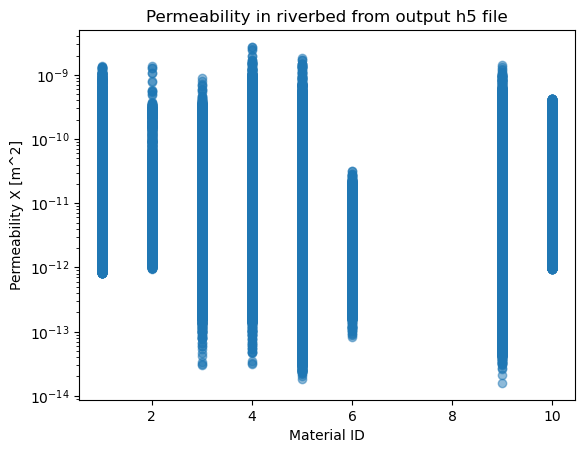

In [25]:
# Plot permeability in riverbed
fig = plt.figure()
# Plotting
plt.scatter(filtered_material_ID, filtered_permeability_x, alpha=0.5)
plt.title('Permeability in riverbed from output h5 file')
plt.ylabel('Permeability X [m^2]')
plt.xlabel('Material ID')
plt.yscale('log')
plt.show() 

## extract permeability from input file

In [7]:
# Read data from HDF5 files
filepath1 = '/pscratch/sd/z/zc727/model_perm/HFR-model-100m-flow_perm.h5'
#filepath1 = '/pscratch/sd/z/zc727/'+'test/perm_test.h5'
with h5.File(filepath1, 'r') as input_h5:
    first_group = input_h5[list(input_h5.keys())[0]]
    permeability_x_output = first_group['Permeability X [m^2]'][:]
    material_id = first_group['Material ID'][:]
    coord_vertices = input_h5['Domain/Vertices'][:]
    cell_centroid_x = input_h5['Domain/XC'][:]
    cell_centroid_y = input_h5['Domain/YC'][:]
    cell_centroid_z = input_h5['Domain/ZC'][:]

filepath0 = '/global/homes/z/zc727/HFR/data/perm_data.h5'
with h5.File(filepath0, 'r') as input_h5:
    permeability_x_input = input_h5['perm_meanX'][:]
    
filepath2 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID.h5'    
with h5.File(filepath2, 'r') as input_h5:
    cell_list = input_h5['Domain/Cells'][:]

# Create cell_centroid array
cell_centroid = np.vstack((cell_centroid_x, cell_centroid_y, cell_centroid_z)).T

# Read river geometry from shapefile
fname_river_shp = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/river_geometry_watershed.shp'
river_shp = shapefile.Reader(fname_river_shp) 
river_poly = Polygon(river_shp.shapes()[0].points)

# Determine river_idx for each cell
river_idx = [river_poly.contains(Point(cell_centroid[i, 0], cell_centroid[i, 1]))
             for i in range(cell_centroid.shape[0])]

# Filter the cells where river_idx is True
filtered_cell_list = [cell_list[i] for i in range(len(cell_list)) if river_idx[i]]
filtered_permeability_x_output = [permeability_x_output[i] for i in range(len(permeability_x_output)) if river_idx[i]]
filtered_permeability_x_input = [permeability_x_input[i] for i in range(len(permeability_x_input)) if river_idx[i]]
filtered_material_ID = [material_id[i] for i in range(len(material_id)) if river_idx[i]]

# Create VTK Points
points = vtk.vtkPoints()
for vertex in coord_vertices:
    points.InsertNextPoint(vertex[0], vertex[1], vertex[2])

# Adjust the vertex order in each cell for vtkWedge and adjust IDs to 0-based
corrected_cell_list = []
for cell in filtered_cell_list:
    number_of_vertices = cell[0]
    if number_of_vertices == 6:
        corrected_cell = [number_of_vertices, cell[1] - 1, cell[3] - 1, cell[2] - 1, cell[4] - 1, cell[5] - 1, cell[6] - 1]
        corrected_cell_list.append(corrected_cell)

# Create a VTK Unstructured Grid
unstructured_grid = vtk.vtkUnstructuredGrid()
unstructured_grid.SetPoints(points)

# Add cells to the grid
for cell in corrected_cell_list:
    number_of_vertices = cell[0]
    if number_of_vertices == 6:
        wedge = vtk.vtkWedge()
        for i in range(6):
            wedge.GetPointIds().SetId(i, cell[i + 1])
        unstructured_grid.InsertNextCell(wedge.GetCellType(), wedge.GetPointIds())

# Convert filtered permeability data to log scale and create VTK array
log_filtered_permeability_x_output = np.log10(np.array(filtered_permeability_x_output))
log_filtered_permeability_x_input = np.log10(np.array(filtered_permeability_x_input))


#filtered_permeability_array = numpy_support.numpy_to_vtk(log_filtered_permeability_x, deep=True)
#filtered_permeability_array.SetName("PermeabilityX logscale")

# Add the log scale Permeability data to the cells in the grid
#unstructured_grid.GetCellData().SetScalars(filtered_permeability_array)

# Write the data to a VTK file
#writer = vtk.vtkXMLUnstructuredGridWriter()
#writer.SetFileName("/global/homes/z/zc727/HFR/data/riverbed_permeability_input.vtu")
#writer.SetInputData(unstructured_grid)
#writer.Write()

#print("File output.vtu written successfully.")

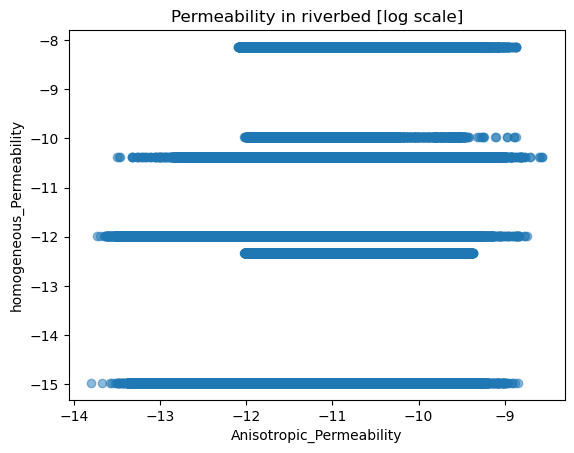

In [9]:
# Plot permeability in riverbed
fig = plt.figure()
# Plotting
plt.scatter(log_filtered_permeability_x_input, log_filtered_permeability_x_output, alpha=0.5)
plt.title('Permeability in riverbed [log scale]')
plt.ylabel('homogeneous_Permeability')
plt.xlabel('Anisotropic_Permeability')
#plt.yscale('log')
plt.show() 